# 5. Campaigns and fault detection

`penicillium.scenarios` builds whole data sets in one call: many batches, simulated in parallel, in tidy tables with
labels. This notebook generates a fault campaign and builds a multiway PCA (MPCA) monitoring model on it, in three
stages on three separate sets of batches:

1. **Training** (normal batches only): the model of normal operation, its number of components and its alarm limits;
2. **Validation**: the alarm rule that decides when a batch is faulty;
3. **Test** (batches never used before, including two fault types left out of validation): the performance, first per
   batch, then per sample.

**Purpose.** The example shows what the package makes possible in a situation that is typical in industry,
where only a small set of normal batches and a few faulty batches is available (here 14 normal and 14 faulty
test batches, 2 per fault). It does not assess the quality of the monitor. The monitor is a standard approach of
multivariate statistical process control (MSPC): a multiway PCA model with the SPE and Hotelling's T² statistics
and alarm limits fitted on normal batches.

**You need:** scikit-learn for the PCA model. The two campaigns have 176 batches in all; the `fast` extra makes
them much quicker to simulate.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

from sklearn.decomposition import PCA

from penicillium import INPUTS, scenarios

camp = scenarios.fault_campaign(n_normal=124, n_per_fault=6, seed=0)
print(camp.description)
camp.batches.head()

fault_campaign(seed=0)


,batch_id,seed,kind,fault,fault_name,batch_length_h,total_yield_kg,final_penicillin_g_per_L,fault_onset_h
0,1,1,normal,0,NONE,230.0,3601.651936,30.779610,NaN
1,2,2,normal,0,NONE,230.0,2439.555278,17.983277,NaN
2,3,3,normal,0,NONE,230.0,2224.212428,16.661335,NaN
3,4,4,normal,0,NONE,230.0,1694.403717,12.334096,NaN
4,5,5,normal,0,NONE,230.0,2338.979824,17.428423,NaN


A `Campaign` has four parts:

- `camp.batches`: one row per batch (seed, fault, yield, fault onset);
- `camp.samples`: one row per batch and sample, with `fault_active` labels and every channel;
- `camp.lab`: lab results in long form, with sampling and reporting times;
- `camp.raman`: spectra, when recorded.

`camp.online()` keeps only what a plant measures online. `camp.split` splits **by batch**, stratified by fault, so
that no batch appears in both sets; here we need three sets and two fault types kept out of validation, so we assign
the batches ourselves, again by batch.

In [2]:
print(camp.batches.groupby("fault_name")["total_yield_kg"].agg(["count", "mean"]).round(0))
online = camp.online().reset_index(drop=True)
print(online.shape)
online.head(3)

                    count    mean
fault_name                       
AERATION                6  1282.0
BASE_FLOW               6  2673.0
COOLANT_FLOW            6  2932.0
NONE                  124  2943.0
PH_SENSOR               6  3540.0
PRESSURE                6  1995.0
SUBSTRATE_FEED          6  1548.0
TEMPERATURE_SENSOR      6  2765.0
(190900, 26)


,batch_id,time_h,kind,fault,fault_active,Fs,Foil,Fg,pressure,discharge,...,RPM,DO2,O2,V,Wt,pH,T,CO2outgas,OUR,CER
0,1,0.2,normal,0,0,8.0,22.0,30.0,0.6,-0.0,...,100.0,14.628722,0.195207,57477.998714,61542.305646,6.483670,297.536560,0.084083,0.519948,0.030943
1,1,0.4,normal,0,0,8.0,22.0,30.0,0.6,-0.0,...,100.0,14.606377,0.203621,57476.760865,61545.543519,6.474232,297.851098,0.094944,0.073636,0.034945
2,1,0.6,normal,0,0,8.0,22.0,30.0,0.6,-0.0,...,100.0,14.573175,0.205398,57477.653040,61550.907628,6.478640,297.835225,0.098746,-0.022055,0.036346


## Three sets of batches

Neighbouring samples are nearly identical, so the sets are formed from whole batches: a split by sample would leak
test batches into training.

| Set | Normal (NOC) batches | Faulty batches | Used for |
|---|---|---|---|
| Training | 100 | – | scaling, PCA model, number of components, alarm limits |
| Validation | 20 | 20: 4 each of faults 1, 2, 3, 4 and 7 | alarm rule |
| Test | 14 | 14: 2 each of faults 1–5, 7 and 8 | performance |

Faults 5 (coolant flow) and 8 (pH sensor drift) are kept out of validation, so the test also shows how the monitor
handles fault types it was not tuned on (the other 4 batches of each are not used). Ten of the normal test batches come
from a second campaign: campaign RNG seeds never overlap, so these are new batches.

In [3]:
N_TRAIN, N_VAL = 100, 20
UNSEEN = (5, 8)
rng = np.random.default_rng(1)
b = camp.batches
split = {}
for i, bid in enumerate(rng.permutation(b[b.fault == 0].batch_id.to_numpy())):
    split[int(bid)] = "train" if i < N_TRAIN else ("val" if i < N_TRAIN + N_VAL else "test")
for f, g in b[b.fault != 0].groupby("fault"):
    for i, bid in enumerate(rng.permutation(g.batch_id.to_numpy())):
        if f in UNSEEN:
            split[int(bid)] = "test" if i < 2 else "unused"
        else:
            split[int(bid)] = "val" if i < 4 else "test"

# Ten more normal test batches from a second campaign, with batch IDs shifted to keep them unique
extra = scenarios.fault_campaign(n_normal=10, n_per_fault=0, faults=(), seed=1)
off = int(b.batch_id.max()) + 1000
on2, b2 = extra.online().copy(), extra.batches.copy()
on2["batch_id"] += off
b2["batch_id"] += off
split.update({int(bid): "test" for bid in b2.batch_id})
online = pd.concat([online, on2], ignore_index=True)
b = pd.concat([b, b2], ignore_index=True)
online["set"] = online.batch_id.map(split)

# Sensor faults (7, 8) are labelled for the whole batch (IndPenSim's convention); the drift starts at 40 h
online["active"] = np.where(online.fault.isin([7, 8]), (online.time_h > 40.0).astype(int), online.fault_active)
names = b.set_index("fault")["fault_name"].to_dict()
b.assign(set=b.batch_id.map(split)).groupby(["set", "fault_name"]).size().unstack(fill_value=0)

fault_name,AERATION,BASE_FLOW,COOLANT_FLOW,NONE,PH_SENSOR,PRESSURE,SUBSTRATE_FEED,TEMPERATURE_SENSOR
set,,,,,,,,
test,2,2,2,14,2,2,2,2
train,0,0,0,100,0,0,0,0
unused,0,0,4,0,4,0,0,0
val,4,4,0,20,0,4,4,4


## Stage 1: the model of normal operation

The model uses the four controller outputs (`Fa`, `Fb`, `Fc`, `Fh`) and the nine online measurements. The recipe-set
feeds are left out because they are identical in every normal batch, and the agitator speed is constant. Each variable
is centred and scaled **per time point** with the normal training batches, so the model knows what is normal at each
stage of the batch. The batches × samples × variables array is then unfolded variable-wise (one row per batch and
sample) and a PCA model is fitted to it.

In [4]:
features = [c for c in scenarios.ONLINE_CHANNELS if c != "RPM" and c not in INPUTS]
train = online[online.set == "train"]

# Mean and spread of every variable at every sample time, over the training batches. The spread is floored at 10 % of
# the variable's overall spread: at some times (the harvest draws, for example) all normal batches agree almost
# exactly, and dividing by that tiny spread would turn any small deviation into a huge one.
ref = train.groupby("time_h")[features]
floor = 0.1 * train[features].std()
mean, sd = ref.mean(), ref.std().fillna(0).clip(lower=floor, axis=1)


def scaled(frame):
    x = frame.set_index("time_h")[features]
    return ((x - mean.loc[x.index].to_numpy()) / sd.loc[x.index].to_numpy()).to_numpy()


Z_train, Z = scaled(train), scaled(online)
pca = PCA().fit(Z_train)
print(features)
print(f"{Z_train.shape[0]} training samples x {Z_train.shape[1]} variables")

['Fa', 'Fb', 'Fc', 'Fh', 'DO2', 'O2', 'V', 'Wt', 'pH', 'T', 'CO2outgas', 'OUR', 'CER']
115000 training samples x 13 variables


**Number of components: scree test.** Plot the variance explained by each component and look for the elbow, where
the curve flattens. To make the choice reproducible, take the elbow as the point farthest from the straight line
joining the first and the last point of the curve, and keep the components before it.

elbow at component 4: keep 3 components, 64% of the variance


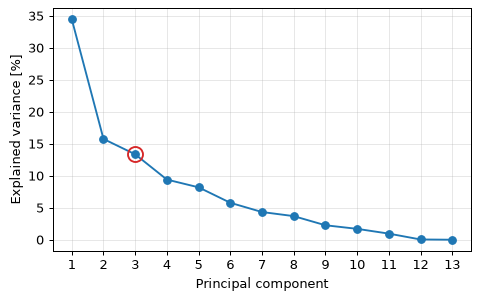

In [5]:
ev = pca.explained_variance_ratio_
k = np.arange(1, len(ev) + 1)
dist = np.abs((ev[-1] - ev[0]) * k - (k[-1] - 1) * ev + k[-1] * ev[0] - ev[-1]) / np.hypot(ev[-1] - ev[0], k[-1] - 1)
elbow = int(k[np.argmax(dist)])
A = elbow - 1

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(k, 100 * ev, "o-")
ax.plot([A], [100 * ev[A - 1]], "o", ms=12, mfc="none", mec="tab:red", mew=1.5)
ax.set(xlabel="Principal component", ylabel="Explained variance [%]", xticks=k)
print(f"elbow at component {elbow}: keep {A} components, {ev[:A].sum():.0%} of the variance")

**Statistics and alarm limits.** Every sample gets a squared prediction error (SPE, distance from the model plane)
and a Hotelling's T² (distance within it). The alarm limit of each is its 95th percentile on the training samples. These are the samples the model was
fitted on, not held-out normal batches, so the limits may be tight for new batches; this is a limitation of
this simple rule.

In [6]:
P, lam = pca.components_[:A].T, pca.explained_variance_[:A]


def statistics(z):
    t = z @ P
    return ((z - t @ P.T) ** 2).sum(axis=1), (t**2 / lam).sum(axis=1)


spe_train, t2_train = statistics(Z_train)
spe_lim, t2_lim = np.percentile(spe_train, 95), np.percentile(t2_train, 95)
spe, t2 = statistics(Z)
online["SPE"], online["T2"] = spe / spe_lim, t2 / t2_lim  # 1 = alarm limit
print(f"SPE limit {spe_lim:.2f}, T2 limit {t2_lim:.2f}")

SPE limit 11.65, T2 limit 9.55


## Stage 2: the alarm rule

By construction, 5 % of the samples of a normal batch exceed each limit, and since consecutive samples are correlated
they do so in runs. A single sample above a limit is therefore not enough to call a batch faulty. The rule: a batch is
faulty when at least **L consecutive samples** lie above the T² limit, or at least L consecutive samples lie above the
SPE limit. L is chosen on the validation batches, to maximise the balanced accuracy: the mean of the share of normal
batches without an alarm and the share of faulty batches with one. On these 40 validation batches the
balanced accuracy is the same for every L from 32 to 46, so the choice of L is flat; the shortest is taken,
because it gives the earliest alarms. A rule that needs L consecutive samples cannot alarm in less than L
samples (6.4 h for L = 32).

best balanced accuracy 97.5% for L = 32-46; using L = 32 (6.4 h)


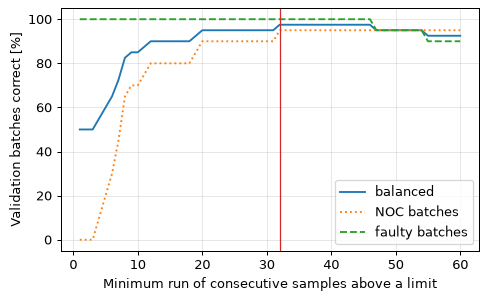

In [7]:
def run_lengths(above):
    """Length of the run of consecutive True values ending at each sample."""
    out, n = np.zeros(len(above), int), 0
    for i, a in enumerate(above):
        n = n + 1 if a else 0
        out[i] = n
    return out


# For every validation and test batch: times, longest current run above a limit (SPE or T2), fault, fault-active mask
runs = {}
for bid, g in online[online.set.isin(["val", "test"])].groupby("batch_id"):
    r = np.maximum(run_lengths(g.SPE.to_numpy() > 1), run_lengths(g.T2.to_numpy() > 1))
    runs[bid] = (g.time_h.to_numpy(), r, int(g.fault.iloc[0]), g.active.to_numpy() == 1)


def first_alarm(bid, L):
    t, r, _, _ = runs[bid]
    hit = np.flatnonzero(r >= L)
    return float(t[hit[0]]) if len(hit) else None


def batch_scores(which, L):
    ids = [bid for bid in runs if split[bid] == which]
    noc = np.mean([first_alarm(i, L) is None for i in ids if runs[i][2] == 0])
    faulty = np.mean([first_alarm(i, L) is not None for i in ids if runs[i][2] != 0])
    return (noc + faulty) / 2, noc, faulty


Ls = np.arange(1, 61)
val = pd.DataFrame(
    [batch_scores("val", L) for L in Ls], index=Ls, columns=["balanced", "NOC batches", "faulty batches"]
)
best = val.balanced.max()
L = int(val.index[val.balanced == best].min())  # the shortest of the best: earliest alarms
ax = (100 * val).plot(style=["-", ":", "--"], figsize=(6, 3.5))
ax.axvline(L, color="tab:red", lw=1)
ax.set(xlabel="Minimum run of consecutive samples above a limit", ylabel="Validation batches correct [%]")
print(
    f"best balanced accuracy {best:.1%} for L = {val.index[val.balanced == best].min()}-"
    f"{val.index[val.balanced == best].max()}; using L = {L} ({0.2 * L:.1f} h)"
)

## Stage 3: results on the test batches

**Per batch.** A normal batch is correct when it raises no alarm, a faulty batch when it raises one.

In [8]:
test_ids = [bid for bid in runs if split[bid] == "test"]
rows = []
for bid in test_ids:
    t, r, f, active = runs[bid]
    first = first_alarm(bid, L)
    alarm = r >= L  # sample-level alarm state
    starts = t[np.flatnonzero(active & ~np.r_[False, active[:-1]])] - 0.2  # start of each fault window
    window = starts[starts < first].max() if f and first is not None and (starts < first).any() else np.nan
    rows.append(
        {
            "batch_id": bid,
            "fault": names[f],
            "seen in validation": f not in UNSEEN,
            "flagged": first is not None,
            "first alarm [h]": first,
            "first fault window [h]": starts.min() if f else np.nan,
            "delay from window start [h]": (first - window) if first is not None else np.nan,
            "samples scored in alarm": alarm[active].mean() if f else alarm.mean(),
        }
    )
res = pd.DataFrame(rows)
noc, faulty = res[res.fault == "NONE"], res[res.fault != "NONE"]
print(f"normal batches passed: {(~noc.flagged).sum()} of {len(noc)}")
print(f"faulty batches flagged: {faulty.flagged.sum()} of {len(faulty)}")
print(f"all test batches correct: {(~noc.flagged).sum() + faulty.flagged.sum()} of {len(res)}")
print("false alarms in normal batches at", noc.loc[noc.flagged, "first alarm [h]"].round(1).tolist(), "h")
early = faulty[faulty["first alarm [h]"] <= faulty["first fault window [h]"]]
print(
    "faulty batches flagged before their first fault window:",
    early[["batch_id", "fault", "first alarm [h]"]].values.tolist(),
)

normal batches passed: 12 of 14
faulty batches flagged: 14 of 14
all test batches correct: 26 of 28
false alarms in normal batches at [72.2, 20.4] h
faulty batches flagged before their first fault window: [[133, 'PRESSURE', 24.0]]


**Per sample.** For normal batches, the share of samples in alarm (false alarms); for faulty batches, the share of the
samples in which the fault acts that are in alarm. The delay is measured from the start of the fault window in which
the alarm is raised.

In [9]:
summary = res.groupby("fault", sort=False).agg(
    batches=("batch_id", "size"),
    seen=("seen in validation", "first"),
    flagged=("flagged", "sum"),
    samples_in_alarm=("samples scored in alarm", "mean"),
    median_delay_h=("delay from window start [h]", "median"),
)
correct = np.where(res.fault == "NONE", 1 - res["samples scored in alarm"], res["samples scored in alarm"])
print(f"samples classified correctly, mean over the test batches: {correct.mean():.0%}")
summary.round(3)

samples classified correctly, mean over the test batches: 67%


,batches,seen,flagged,samples_in_alarm,median_delay_h
fault,,,,,
NONE,14,True,2,0.003,NaN
AERATION,2,True,2,0.278,6.4
PRESSURE,2,True,2,0.759,6.4
SUBSTRATE_FEED,2,True,2,0.251,4.2
BASE_FLOW,2,True,2,0.299,13.1
COOLANT_FLOW,2,False,2,0.505,10.2
TEMPERATURE_SENSOR,2,True,2,0.057,76.3
PH_SENSOR,2,False,2,0.240,68.5


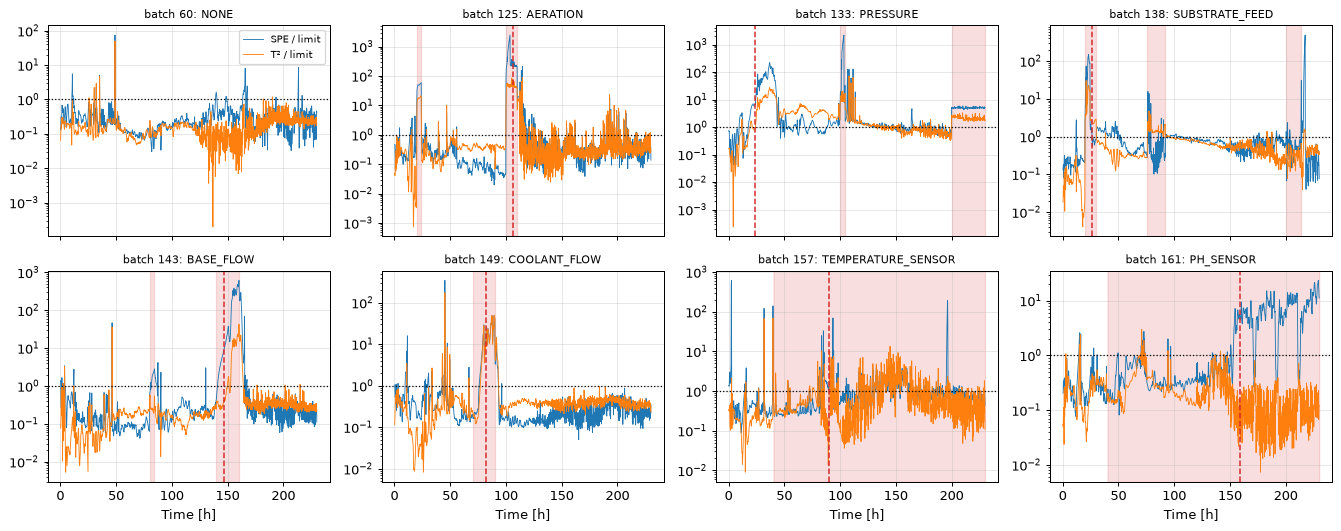

In [10]:
# One normal test batch and one test batch of every fault; dashed: the batch alarm
tst = online[online.set == "test"]
shown = [tst[tst.fault == 0].batch_id.iloc[0]] + [g.batch_id.iloc[0] for f, g in tst.groupby("fault") if f != 0]
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex=True)
for ax, bid in zip(axes.flat, shown):
    g = tst[tst.batch_id == bid]
    ax.semilogy(g.time_h, g.SPE, lw=0.7, label="SPE / limit")
    ax.semilogy(g.time_h, g.T2, lw=0.7, label="T² / limit")
    ax.axhline(1, color="k", ls=":", lw=1)
    ax.fill_between(
        g.time_h, 0, 1, where=g.active == 1, transform=ax.get_xaxis_transform(), color="tab:red", alpha=0.15
    )
    if (first := first_alarm(bid, L)) is not None:
        ax.axvline(first, color="tab:red", ls="--", lw=1.2)
    ax.set_title(f"batch {bid}: {names[g.fault.iloc[0]]}", fontsize=9)
axes.flat[0].legend(fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("Time [h]")
fig.tight_layout()

Shaded: samples where the fault acts; dotted: the alarm limit; dashed: the batch alarm. What the numbers show:

- **Per batch** the count is at batch level: a faulty batch counts as flagged if it raises an alarm at any
  time. All 14 faulty batches raise one, including the two fault types the monitor never saw, and 12 of the 14
  normal batches pass. For one back-pressure batch, however, the alarm comes at 24 h, 76 h before its first fault
  window, because its statistics leave the normal region early: that alarm is not caused by the fault, and it is
  not a detection of the fault. Counting only alarms raised after the fault starts gives 13 of 14, unless that
  batch also alarms inside its fault windows (not yet checked); the example will be re-scored that way, with
  pre-fault alarms reported as false alarms.
- **The intervals are wide.** With 14 batches of each kind, the 95 % Clopper–Pearson intervals are 77–100 % for
  14 of 14 faulty batches flagged (66–100 % for 13 of 14), 57–98 % for 12 of 14 normal batches passed, and
  76–99 % for 26 of 28 test batches correct. With 2 batches per fault, 2 of 2 has an interval of 16–100 %, so the
  rows per fault in the table above are illustrations, not estimates. For a precise estimate for your own
  monitor, generate a larger test set: 1000 batches per class take a few minutes with the same call.
- **Per sample** the shares are much lower, and the delays above are delays of this alarm rule. The rule has
  three limitations: it cannot alarm in less than L = 32 samples (6.4 h), so fault windows shorter than that
  cannot raise an alarm at all; its limits are percentiles of the training samples, not of held-out normal
  batches; and L was chosen where the validation accuracy is flat (32 to 46). The first windows of the aeration,
  back-pressure and base-flow faults last 4 h, so those batches are flagged in their second window. An EWMA or
  CUSUM chart on the SPE and T² statistics, with limits set on held-out normal batches for a stated in-control
  run length, can alarm within a few samples of a large shift.
- **The fault windows are fixed.** Each fault type acts in the same windows in every batch, as in IndPenSim
  (see [Faults](../faults.md)), so detection delays reflect those windows, and a classifier could infer the
  fault type from the batch time instead of from the process.
- **The sensor-fault records show the true values.** With faults 7 and 8 the recorded `T` and `pH` are the broth
  values, not the drifting reading the controller saw, which makes detection easier than on a plant. Even so the
  slow drifts are the hardest: the control loop hides them, and the broth moves by at most 0.4 K or 0.1 pH units.
- **Labels.** The batch-level score uses the batch's `fault` code; the sample-level score uses `fault_active` for
  process faults and, for sensor faults, the samples after 40 h, when the drift acts (`fault_active` is 1 for the
  entire batch with sensor faults; see [fault labels](../scenarios.md#fault-labels-in-campaigns)).
- **OUR and CER** are among the variables of the model. They follow IndPenSim's off-gas formulas, and their
  absolute scale is not consistent with the model's oxygen uptake: they work as monitoring signals, but a
  respiratory quotient computed from them should not be read quantitatively
  ([Lab data and Raman spectra](../measurements.md)).

Natural next steps are contribution plots for diagnosis, dynamic or batch-wise unfolded models, and alarm rules that
use both statistics together.

## Other campaigns and saving

- `scenarios.soft_sensor_campaign(...)`: Raman spectra and delayed lab data ([tutorial 6](06_raman_soft_sensor.ipynb));
- `scenarios.goldrick2019_campaign(...)`: the structure of the published 100-batch IndPenSim data set;
- `scenarios.control_benchmark(...)`: a fixed test set for control policies ([tutorial 7](07_reinforcement_learning.ipynb)).

Any campaign accepts `measurement_noise=MeasurementNoise.typical()` and saves to Parquet and CSV:

In [11]:
import tempfile
from pathlib import Path

out = camp.save(Path(tempfile.mkdtemp()) / "fault_campaign")
print(sorted(p.name for p in out.iterdir()))

['batches.csv', 'campaign.json', 'lab.csv', 'samples.parquet']


For your own designs (any mix of seeds, configs and recipes), build a list of `BatchSpec` and call
`simulate_batches`, as in [tutorial 2](02_recipes_and_control.ipynb). More in
[Campaigns and datasets](../scenarios.md).

**Next:** [A Raman soft sensor](06_raman_soft_sensor.ipynb).